# C1 BERT và C2 RoBERTa

Notebook có đầu ra thực đã lưu. Run All kiểm checkpoint và tính lại bảng báo cáo từ xác suất đã lưu, sau đó suy luận thật từ sáu checkpoint. C3 có notebook 05 riêng. Không huấn luyện trong Run All; mã huấn luyện chung ở `scripts/transformers/train_transformer.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root, benchmark, replay_split
from src.models.transformer import run_folder, load_transformer_run, METRIC_NAMES
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.datasets.goemotions import multi_hot
ARTIFACTS = artifacts_root()
verified, frames, labels = benchmark(str(ARTIFACTS))
SEEDS = (42, 123, 2026)
pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0])
print('Đã kiểm: 72 dòng kết quả và 9 checkpoint; ba seed cho mỗi C.')
ARCHITECTURES = ('bert', 'roberta')

PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật


PASS C: bert seed 42


PASS C: bert seed 123


PASS C: bert seed 2026


...

PASS C: roberta seed 2026


PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


Python: 3.13.9
Đã kiểm: 72 dòng kết quả và 9 checkpoint; ba seed cho mỗi C.


## 1 Cấu hình và lịch sử huấn luyện
Checkpoint chọn bằng Macro-F1 validation tại 0,5. Mỗi kiến trúc giữ đủ ba seed.

,architecture,seed,epochs,learning_rate,batch_size,max_length,selected_epoch
0,bert,42,4,0.00005,16,128,4
1,bert,123,4,0.00005,16,128,4
2,bert,2026,4,0.00005,16,128,4
3,roberta,42,3,0.00002,16,128,3
4,roberta,123,3,0.00002,16,128,3
5,roberta,2026,3,0.00002,16,128,3


,architecture,seed,epoch,train_loss,macro_f1,micro_f1
0,bert,42,1,0.145163,0.289326,0.534587
1,bert,42,2,0.083471,0.416234,0.563140
2,bert,42,3,0.064921,0.440199,0.576717
3,bert,42,4,0.047237,0.464148,0.575977
4,bert,123,1,0.144342,0.311764,0.523572
5,bert,123,2,0.084000,0.395829,0.565323
6,bert,123,3,0.066395,0.474919,0.586256
7,bert,123,4,0.049562,0.477294,0.583900
8,bert,2026,1,0.144340,0.297917,0.531598
9,bert,2026,2,0.084097,0.414675,0.574155


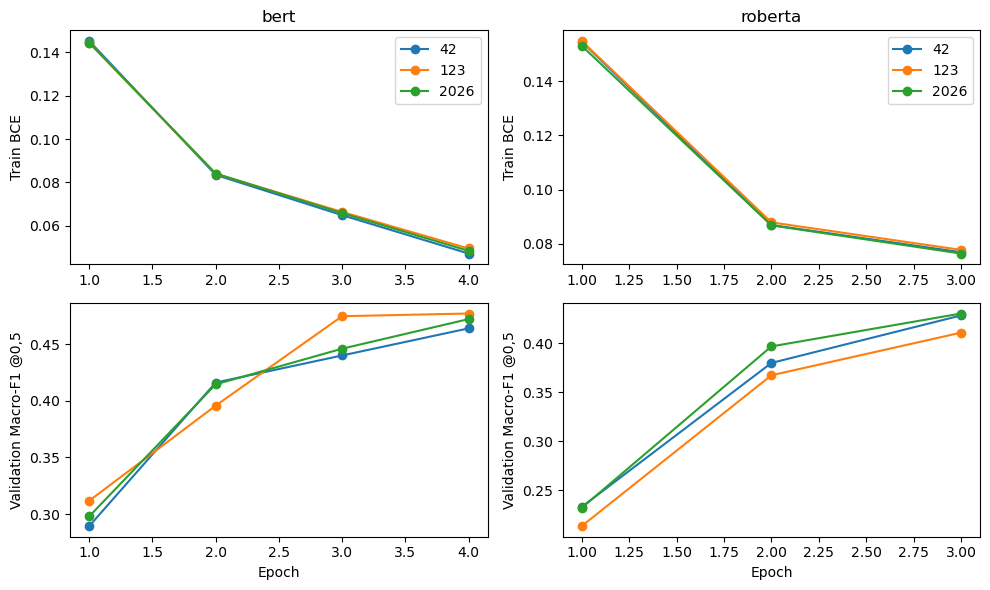

In [2]:
metadata = [load_transformer_run(run_folder(ARTIFACTS,a,s),require_full=True) for a in ARCHITECTURES for s in SEEDS]
display(pd.DataFrame([dict(architecture=m['architecture'],seed=m['seed'],selected_epoch=m['selected_epoch'],**m['config']) for m in metadata])[['architecture','seed','epochs','learning_rate','batch_size','max_length','selected_epoch']])
history = pd.DataFrame([dict(architecture=m['architecture'],seed=m['seed'],**h) for m in metadata for h in m['history']])
display(history[['architecture','seed','epoch','train_loss','macro_f1','micro_f1']])
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(10,6))
for j,a in enumerate(ARCHITECTURES):
    for s,g in history[history.architecture==a].groupby('seed'):
        axes[0,j].plot(g.epoch,g.train_loss,'-o',label=str(s))
        axes[1,j].plot(g.epoch,g.macro_f1,'-o',label=str(s))
    axes[0,j].set_title(a);axes[0,j].set_ylabel('Train BCE')
    axes[1,j].set(xlabel='Epoch',ylabel='Validation Macro-F1 @0,5');axes[0,j].legend()
fig.tight_layout();plt.show()

## 2 Bảng kết quả khớp báo cáo
Tính từ scores đã kiểm ID và thứ tự nhãn; mean và std mẫu ddof=1. Báo cáo chỉ trình bày 0,5 và ngưỡng riêng.

In [3]:
records=pd.DataFrame(verified['records'])
means=pd.DataFrame(verified['averages'])
mask=means.system.isin(['C_bert','C_roberta']) & means.threshold_mode.isin(['fixed','tuned'])
display(means[mask][['system','split','threshold_mode','n_runs','macro_f1_mean','macro_f1_std','micro_f1_mean','micro_f1_std','hamming_loss_mean']])
for a in ARCHITECTURES:
    for mode in ('fixed','tuned'):
        r=records[(records.system=='C_'+a)&(records.split=='test')&(records.threshold_mode==mode)]
        row=means[(means.system=='C_'+a)&(means.split=='test')&(means.threshold_mode==mode)].iloc[0]
        assert set(r.seed.astype(int))==set(SEEDS)
        for k in METRIC_NAMES:
            np.testing.assert_allclose([r[k].mean(),r[k].std(ddof=1)],[row[k+'_mean'],row[k+'_std']],atol=1e-12,rtol=0)
print('PASS: bảng từ scores khớp báo cáo; không chọn lại ngưỡng trên test.')

,system,split,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean
18,C_bert,validation,fixed,3,0.471263,0.006640,0.580680,0.004165,0.032243
20,C_bert,validation,tuned,3,0.528959,0.005978,0.599305,0.001610,0.036509
21,C_bert,test,fixed,3,0.472001,0.004524,0.581982,0.004040,0.031843
23,C_bert,test,tuned,3,0.503752,0.009682,0.590001,0.002851,0.037259
24,C_roberta,validation,fixed,3,0.423441,0.010773,0.576705,0.003299,0.029977
26,C_roberta,validation,tuned,3,0.507239,0.017981,0.614446,0.004705,0.035458
27,C_roberta,test,fixed,3,0.421943,0.008810,0.580344,0.000878,0.029520
29,C_roberta,test,tuned,3,0.487201,0.015562,0.604847,0.005666,0.036460


PASS: bảng từ scores khớp báo cáo; không chọn lại ngưỡng trên test.


## 3 Suy luận thật trên test
Mỗi checkpoint chạy đủ 5.427 câu. Cột sai lệch ghi nhận thay đổi số học nếu dtype hoặc kernel khác. Bảng báo cáo ở mục 2 dùng đúng scores của lượt đã chốt; không thay bằng một lượt suy luận có sai lệch.

In [4]:
fresh=pd.concat([replay_split(ARTIFACTS,'C_'+a,s,'test') for a in ARCHITECTURES for s in SEEDS],ignore_index=True)
assert len(fresh)==18 and (fresh.n_samples==5427).all()
display(fresh[fresh.threshold_mode.isin(['fixed','tuned'])])
print('Checkpoint đã suy luận:',fresh.groupby(['system','seed']).ngroups)
print('Sai lệch score lớn nhất:',fresh.score_max_abs_diff.max())

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff,score_tolerance,changed_label_decisions,exact_metric_match
0,C_bert,42,test,fixed,5427,0.469701,0.583212,0.528458,0.432855,0.637608,0.537368,0.031990,0.0,0.0,0.005,0,True
2,C_bert,42,test,tuned,5427,0.494982,0.587676,0.507481,0.522209,0.540286,0.644178,0.037649,0.0,0.0,0.005,0,True
3,C_bert,123,test,fixed,5427,0.477212,0.585264,0.575230,0.430576,0.649211,0.532786,0.031450,0.0,0.0,0.005,0,True
5,C_bert,123,test,tuned,5427,0.514141,0.593181,0.527820,0.528055,0.546374,0.648760,0.037063,0.0,0.0,0.005,0,True
6,C_bert,2026,test,fixed,5427,0.469090,0.577470,0.569649,0.426428,0.639417,0.526465,0.032088,0.0,0.0,0.005,0,True
8,C_bert,2026,test,tuned,5427,0.502133,0.589145,0.526799,0.513931,0.547229,0.638015,0.037063,0.0,0.0,0.005,0,True
9,C_roberta,42,test,fixed,5427,0.421270,0.580483,0.564949,0.372683,0.707727,0.492021,0.029620,0.0,0.0,0.005,0,True
11,C_roberta,42,test,tuned,5427,0.483491,0.605672,0.487296,0.510442,0.551590,0.671512,0.036418,0.0,0.0,0.005,0,True
12,C_roberta,123,test,fixed,5427,0.413490,0.579404,0.566240,0.367880,0.718596,0.485385,0.029351,0.0,0.0,0.005,0,True
14,C_roberta,123,test,tuned,5427,0.473829,0.598814,0.466194,0.518650,0.536098,0.678148,0.037846,0.0,0.0,0.005,0,True


Checkpoint đã suy luận: 6
Sai lệch score lớn nhất: 0.0


## 4 Dự đoán câu mới bằng checkpoint đã lưu
Không có gold label nên không tính accuracy cho câu tự soạn.

In [5]:
from src.apps.model_selector import ModelSelector
selector=ModelSelector(ARTIFACTS,ARTIFACTS/'data/processed/transformers/selected_model.json',device='auto')
for key in ARCHITECTURES:
    message,rows=selector.predict('I was worried, but your help made me feel so relieved.',key,'tuned')
    print(key,message)
    display(pd.DataFrame(rows,columns=['label','score','threshold','selected']).head(8))
del selector

bert **Mô hình:** C1 · BERT — mô hình mặc định · seed 123

**Cảm xúc dự đoán:** nervousness, relief


,label,score,threshold,selected
0,nervousness,0.3474,0.30,Có
1,caring,0.3047,0.35,
2,fear,0.2807,0.35,
3,relief,0.2490,0.10,Có
4,joy,0.2410,0.30,
5,realization,0.1357,0.55,
6,approval,0.1058,0.30,
7,excitement,0.0900,0.35,


roberta **Mô hình:** C2 · RoBERTa · seed 2026

**Cảm xúc dự đoán:** caring, joy, relief


,label,score,threshold,selected
0,joy,0.3237,0.25,Có
1,caring,0.3201,0.30,Có
2,sadness,0.1183,0.55,
3,gratitude,0.0889,0.60,
4,relief,0.0825,0.05,Có
5,approval,0.0637,0.15,
6,admiration,0.0500,0.45,
7,disappointment,0.0492,0.20,
